# 14. Validación por vecinos más cercanos y mejoras del modelo base (versión 3)

*Autores: María Carolina Cantillo Orozco (200179105) y Juan Camilo Oñoro Araujo (200177329)*

```{admonition} Qué hace este capítulo
:class: tip
**Pregunta que responde:** ¿el buffer fijo de 1 km mide el escenario que
queremos medir?, ¿qué cambia si la validación se diseña emparejando
distancias al vecino más cercano?, y ¿mejoran el modelo base una logística
ordinal o unos umbrales de decisión ajustados al F1 macro?

**Datos:** la misma partición del capítulo 2 (**257 273** viviendas de
entrenamiento y **65 145** de prueba en 7 bloques de 2 km). El test no cambia.

**Recorrido:** a qué distancia se predice en cada diseño (14.1); validación
kNNDM (14.2); hiperparámetros con esa validación (14.3); test con y sin buffer
(14.4); logística ordinal (14.5); umbrales para el F1 macro (14.6); resumen y
decisión (14.7).
```

**Por qué este capítulo.** El buffer de 1 km del capítulo 8 fue un compromiso: el alcance del
correlograma (2.6 km) vaciaba el entrenamiento y 1 km parecía una franja razonable. Pero un buffer fijo no
dice qué escenario se está midiendo. Siguiendo la sugerencia del profesor (libro de Modelos
Espacio-Temporales, cap. 2: grafos de *k* vecinos más cercanos y una validación que respete la dependencia
espacial), este capítulo mide el escenario con la **distancia al vecino más cercano** y diseña la validación
para que lo reproduzca. Todo lo demás (datos, partición, variables, Pipeline, métricas y test) es idéntico al
capítulo 10.

In [1]:
# Preparación del entorno: mismas importaciones y decisiones del EDA que el cap. 10.
import json
import sys
import time
import warnings
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, recall_score
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline

from src import config as C
from src import graficos as G
from src import modelo as M
from src import particion as P
from src import vecinos as V

G.estilo()
C.aviso_sintetico()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
dec = C.leer_decisiones()
# Resultados de la versión 2 (cap. 10), para comparar con el mismo test.
v2 = json.loads((RAIZ / "datos" / "procesados" / "resultados_modelo.json").read_text(encoding="utf-8"))

In [2]:
# Datos y conjuntos de variables: idénticos al cap. 10.
datos = P.cargar_particion()
vm = dec["variables_modelo"]["valor"]
num_log = dec["num_log"]["valor"]
buffer_km = dec["buffer_km"]["valor"]
q_inf, q_sup = dec["winsorizacion_cuantiles"]["valor"]
min_frec = dec["onehot_min_frecuencia"]["valor"]
train_total = datos[datos.particion == "train"].reset_index(drop=True)
test = datos[datos.particion == "test"].reset_index(drop=True)
# El entrenamiento de la versión 2: sin las viviendas a menos de 1 km del test.
mantener = P.mascara_buffer(train_total[["x_km", "y_km"]].to_numpy(), test[["x_km", "y_km"]].to_numpy(), buffer_km)
train_buf = train_total[mantener].reset_index(drop=True)
conjuntos = {
    "A_fisicas": {"num": vm["numericas"], "cat": vm["categoricas"]},
    "B_fisicas+ubicacion": {"num": vm["numericas"] + vm["espaciales"], "cat": vm["categoricas"]},
}
B = "B_fisicas+ubicacion"
cols_B = conjuntos[B]["num"] + conjuntos[B]["cat"]
y_tt, y_tb, y_te = (d[C.OBJETIVO].to_numpy() for d in (train_total, train_buf, test))
print(f"Train completo: {len(train_total):,} | train de la versión 2 (tras buffer de {buffer_km} km): "
      f"{len(train_buf):,} | test: {len(test):,} en {test.bloque.nunique()} bloques")


def pipeline_logistica(conj, clf=None, **kw):
    """Mismo preprocesamiento del cap. 10; el clasificador puede cambiar (multinomial u ordinal)."""
    nums, cats = conj["num"], conj["cat"]
    prep = M.construir_preprocesador([c for c in nums if c in num_log], [c for c in nums if c not in num_log],
                                     cats, q_inf=q_inf, q_sup=q_sup, min_frecuencia=min_frec)
    return Pipeline([("prep", prep), ("clf", clf if clf is not None else LogisticRegression(max_iter=1000, **kw))])


def xy(df):
    return df[["x_km", "y_km"]].to_numpy()

Train completo: 257,273 | train de la versión 2 (tras buffer de 1.0 km): 144,586 | test: 65,145 en 7 bloques


## 14.1 ¿A qué distancia se predice?

Para cada vivienda que se predice, la pregunta clave es **a qué distancia
está la vivienda más cercana cuyo estrato conoce el modelo**. Con la
autocorrelación del estrato (I de Moran 0.92), esa distancia decide casi todo:
a 50 m el vecino conocido es casi una copia; a 2 km es otro barrio. Se mide
con un punto por edificio (las unidades de un edificio comparten coordenada)
y se pondera por viviendas.

In [3]:
# Un punto por edificio en cada conjunto.
xy_te_g, n_te, _ = V.puntos_unicos(xy(test), test.npn_edificio.to_numpy())
xy_tt_g, n_tt, _ = V.puntos_unicos(xy(train_total), train_total.npn_edificio.to_numpy())
xy_tb_g, n_tb, _ = V.puntos_unicos(xy(train_buf), train_buf.npn_edificio.to_numpy())
# (1) Escenario declarado en el cap. 2: predecir una zona nueva de 2 km cuyo entorno sí se conoce.
d_escenario = V.distancia_vecino(xy_te_g, xy_tt_g)
# (2) Lo que midió el test de la versión 2: el entrenamiento sin las viviendas a < 1 km.
d_test_v2 = V.distancia_vecino(xy_te_g, xy_tb_g)
# (3) La validación cruzada de la versión 2 (bloques + buffer, los mismos folds del cap. 10).
folds_v2 = P.folds_espaciales_con_buffer(train_buf, buffer_km, verbose=False)
d_cv_v2, n_cv_v2 = V.distancias_de_folds(xy(train_buf), train_buf.npn_edificio.to_numpy(), folds_v2)
# (4) Una validación aleatoria por edificios: cada edificio frente a todos los demás.
d_aleatoria = cKDTree(xy_tt_g).query(xy_tt_g, k=2)[0][:, 1]

distancias = {
    "Escenario: zona nueva de 2 km (test → todo train)": (d_escenario, n_te),
    "Test de la versión 2 (test → train tras buffer)": (d_test_v2, n_te),
    "CV de la versión 2 (bloques + buffer de 1 km)": (d_cv_v2, n_cv_v2),
    "CV aleatoria por edificios": (d_aleatoria, n_tt),
}
tabla_dist = pd.DataFrame({k: dict(zip(["p10 (km)", "mediana (km)", "p90 (km)"], V.cuantiles_ponderados(d, w)))
                           for k, (d, w) in distancias.items()}).T
tabla_dist

,p10 (km),mediana (km),p90 (km)
Escenario: zona nueva de 2 km (test → todo train),0.1065,0.4534,0.8194
Test de la versión 2 (test → train tras buffer),1.1029,1.5319,2.0130
CV de la versión 2 (bloques + buffer de 1 km),1.0740,1.4062,2.0748
CV aleatoria por edificios,0.0000,0.0103,0.1091


El escenario que declaró el capítulo 2 es predecir una **zona nueva de 2 km**
cuyo entorno sí está en la base: para la mitad de las viviendas de prueba, la vivienda conocida más cercana
está a menos de **0.45 km** (p90: 0.82 km). El buffer de 1 km cambió ese escenario: el test de la versión 2 se
evaluó con el vecino conocido a una mediana de **1.53 km**, y su validación cruzada a **1.41 km**. Se midió
algo más difícil que lo declarado: predecir un barrio a un kilómetro y medio de cualquier dato. En el otro
extremo, una validación aleatoria por edificios evalúa a 10 m del vecino conocido: casi lo copia (por eso daba
F1 0.62).

## 14.2 Validación kNNDM: folds que imitan el escenario

La **validación cruzada por emparejamiento de distancias al vecino más
cercano** (*k-fold Nearest Neighbour Distance Matching*, kNNDM; Milà et al.
2022; Linnenbrink et al. 2024) arma los folds de modo que la distribución de
esas distancias en la validación se parezca a la del escenario de
predicción. El procedimiento (implementado en `src/vecinos.py`):

1. Se agrupan los edificios de entrenamiento con K-Means en *q* grupos
   compactos y los grupos se reparten en 5 folds estratificados por estrato
   (el mismo algoritmo voraz del cap. 2). Un *q* pequeño da folds grandes y
   lejanos, como bloques; un *q* grande da folds salpicados, como una
   validación aleatoria.
2. Para cada *q* se calcula, para cada edificio, la distancia al edificio
   más cercano de otro fold, y se compara con la distancia del escenario
   mediante la **distancia de Wasserstein** (el área entre las dos curvas de
   distribución acumulada, en km).
3. Se elige el *q* con la menor distancia de Wasserstein.

Es la idea del grafo de **k vecinos más cercanos** del libro de Modelos
Espacio-Temporales (Rubio, cap. 2), aplicada a la validación: el tamaño de la
zona excluida no se fija a mano, sale de la geometría del problema. El
escenario se define solo con las **coordenadas** del test, nunca con su
estrato.

In [4]:
t0 = time.time()
res_knndm = V.knndm(xy(train_total), train_total.npn_edificio.to_numpy(), y_tt, xy_te_g, n_te)
folds_v3 = res_knndm["folds"]
print(f"q elegido = {res_knndm['q']} grupos | Wasserstein = {res_knndm['W']:.3f} km "
      f"(CV aleatoria: {res_knndm['W_loo']:.3f} km) | {time.time() - t0:.0f} s")
for i, (itr, iva) in enumerate(folds_v3):
    print(f"  fold {i}: entrenamiento {len(itr):>7,} | validación {len(iva):>6,} | "
          f"estratos en validación: {np.unique(y_tt[iva]).tolist()}")
distancias["CV kNNDM (versión 3)"] = (res_knndm["d_cv"], res_knndm["pesos_g"])
tabla_dist = pd.DataFrame({k: dict(zip(["p10 (km)", "mediana (km)", "p90 (km)"], V.cuantiles_ponderados(d, w)))
                           for k, (d, w) in distancias.items()}).T
W_v2 = {k: V.wasserstein_distance(d, d_escenario, u_weights=w, v_weights=n_te) for k, (d, w) in distancias.items()}
tabla_dist["Wasserstein al escenario (km)"] = pd.Series(W_v2)
tabla_dist

  q =     5: W = 0.982 km | mediana de G*_j = 1.325 km


  q =     8: W = 0.662 km | mediana de G*_j = 1.032 km


  q =    12: W = 0.564 km | mediana de G*_j = 0.950 km


  q =    16: W = 0.330 km | mediana de G*_j = 0.650 km


  q =    20: W = 0.270 km | mediana de G*_j = 0.600 km


...

  q =  2000: W = 0.376 km | mediana de G*_j = 0.057 km


  q =  3500: W = 0.384 km | mediana de G*_j = 0.048 km


  q =  6000: W = 0.392 km | mediana de G*_j = 0.041 km


q elegido = 30 grupos | Wasserstein = 0.178 km (CV aleatoria: 0.428 km) | 179 s
  fold 0: entrenamiento 207,292 | validación 49,981 | estratos en validación: [1, 2, 3, 4, 5, 6]
  fold 1: entrenamiento 202,661 | validación 54,612 | estratos en validación: [1, 2, 3, 4, 5, 6]
  fold 2: entrenamiento 207,441 | validación 49,832 | estratos en validación: [1, 2, 3, 4, 5, 6]
  fold 3: entrenamiento 207,897 | validación 49,376 | estratos en validación: [1, 2, 3, 4, 5, 6]
  fold 4: entrenamiento 203,801 | validación 53,472 | estratos en validación: [1, 2, 3, 4, 5, 6]


,p10 (km),mediana (km),p90 (km),Wasserstein al escenario (km)
Escenario: zona nueva de 2 km (test → todo train),0.1065,0.4534,0.8194,0.0000
Test de la versión 2 (test → train tras buffer),1.1029,1.5319,2.0130,1.0729
CV de la versión 2 (bloques + buffer de 1 km),1.0740,1.4062,2.0748,1.0331
CV aleatoria por edificios,0.0000,0.0103,0.1091,0.4277
CV kNNDM (versión 3),0.1044,0.4640,1.2273,0.1782


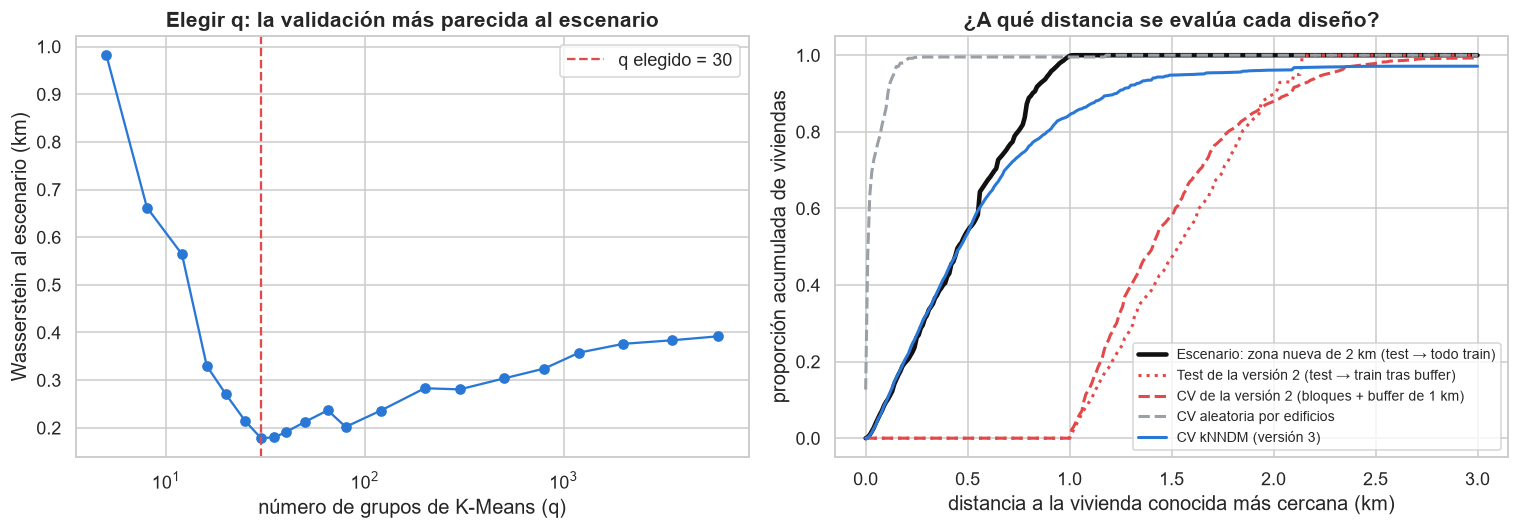

In [5]:
# Izquierda: distancia de Wasserstein según el número de grupos q. Derecha: curvas de
# distribución acumulada de la distancia al vecino conocido más cercano en cada diseño.
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
t = res_knndm["tabla"]
ax[0].plot(t.q, t.W_km, "o-", color="#2a78d6")
ax[0].axvline(res_knndm["q"], color="#e34948", ls="--", label=f"q elegido = {res_knndm['q']}")
ax[0].set_xscale("log")
ax[0].set_xlabel("número de grupos de K-Means (q)")
ax[0].set_ylabel("Wasserstein al escenario (km)")
ax[0].legend()
ax[0].set_title("Elegir q: la validación más parecida al escenario")
rejilla = np.linspace(0, 3, 301)
estilos = {"Escenario: zona nueva de 2 km (test → todo train)": ("#111111", "-", 3),
           "Test de la versión 2 (test → train tras buffer)": ("#e34948", ":", 2),
           "CV de la versión 2 (bloques + buffer de 1 km)": ("#e34948", "--", 2),
           "CV aleatoria por edificios": ("#9aa0a6", "--", 2),
           "CV kNNDM (versión 3)": ("#2a78d6", "-", 2)}
ecdfs = {}
for k, (d, w) in distancias.items():
    _, F = V.ecdf(d, w, rejilla)
    ecdfs[k] = F
    col, ls, lw = estilos[k]
    ax[1].plot(rejilla, F, color=col, ls=ls, lw=lw, label=k)
ax[1].set_xlabel("distancia a la vivienda conocida más cercana (km)")
ax[1].set_ylabel("proporción acumulada de viviendas")
ax[1].legend(fontsize=9, loc="lower right")
ax[1].set_title("¿A qué distancia se evalúa cada diseño?")
plt.tight_layout()
plt.show()

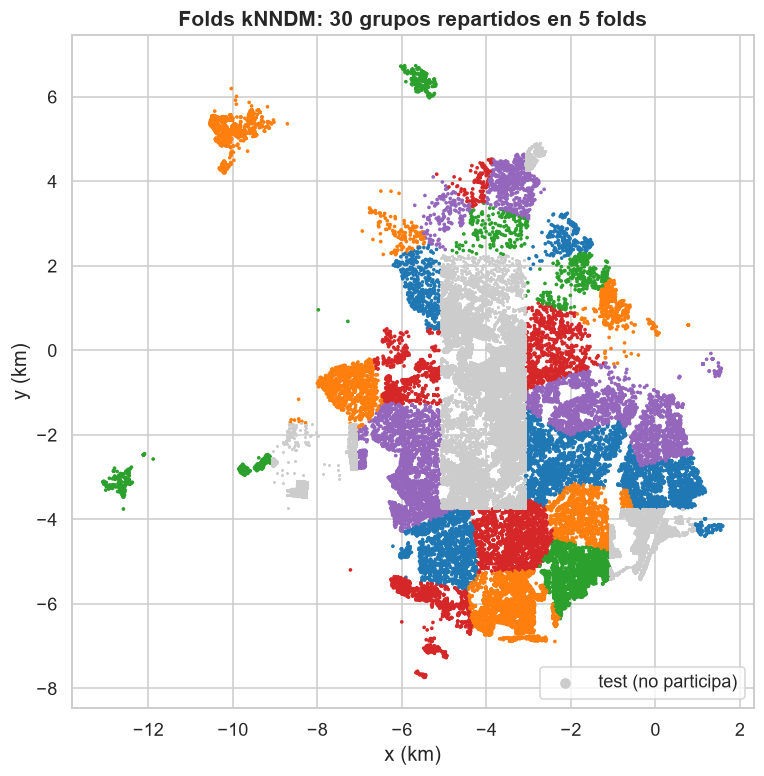

In [6]:
# Mapa de los folds kNNDM (muestra de edificios): grupos compactos repartidos en 5 folds.
fold_g = pd.Series(res_knndm["fold_fila"]).groupby(
    np.unique(train_total.npn_edificio.to_numpy(), return_inverse=True)[1]).first().to_numpy()
rng = np.random.default_rng(C.SEED)
m = rng.choice(len(xy_tt_g), size=min(25_000, len(xy_tt_g)), replace=False)
fig, ax = plt.subplots(figsize=(8, 8))
sc = ax.scatter(xy_tt_g[m, 0], xy_tt_g[m, 1], c=fold_g[m], cmap="tab10", s=2, vmin=0, vmax=9)
ax.scatter(xy_te_g[:, 0], xy_te_g[:, 1], c="#cccccc", s=1, label="test (no participa)")
ax.set_aspect("equal")
ax.set_xlabel("x (km)")
ax.set_ylabel("y (km)")
ax.set_title(f"Folds kNNDM: {res_knndm['q']} grupos repartidos en 5 folds")
ax.legend(loc="lower right", markerscale=6)
plt.show()

La distancia de Wasserstein es mínima con **q = 30 grupos** (0.18 km): folds formados
por grupos compactos de 2 a 3 km repartidos por la ciudad. Con ellos la mediana de la distancia en validación
(0.46 km) coincide con la del escenario (0.45 km); la cola es algo más larga (p90 1.23 frente a 0.82 km), así
que la validación queda un poco del lado conservador. La validación de la versión 2 estaba a 1.03 km del
escenario y la aleatoria a 0.43 km. Los cinco folds tienen entre 49 000 y 55 000 viviendas y los seis estratos
en validación. Del test solo se usaron las coordenadas.

## 14.3 Hiperparámetros con la validación kNNDM

Se repite la búsqueda del cap. 10 (misma rejilla de C y pesos de clase, misma
regla de un error estándar) pero con los folds kNNDM y **sin buffer**: el
entrenamiento de cada fold es todo lo que no está en su validación.

In [7]:
grid = {"clf__C": [0.01, 0.1, 1, 10], "clf__class_weight": [None, "balanced"]}


def regla_1se(cv_results, k=len(folds_v3)):
    """Índice de la combinación más regularizada (menor C) a < 1 SE de la mejor (igual que el cap. 10)."""
    media = np.asarray(cv_results["mean_test_score"], float)
    se = np.asarray(cv_results["std_test_score"], float) / np.sqrt(k)
    i_mejor = int(np.nanargmax(media))
    candidatos = np.flatnonzero(media >= media[i_mejor] - se[i_mejor])
    c_vals = np.asarray(cv_results["param_clf__C"], float)
    finalistas = [i for i in candidatos if c_vals[i] == c_vals[candidatos].min()]
    return int(finalistas[int(np.argmax(media[finalistas]))])


def scores_por_fold(gs, i=None):
    """F1 macro de cada fold para la combinación i (por defecto, la elegida)."""
    i = gs.best_index_ if i is None else i
    return np.array([gs.cv_results_[f"split{f}_test_score"][i] for f in range(len(folds_v3))])


busquedas = {}
for nombre, conj in conjuntos.items():
    t0 = time.time()
    gs = GridSearchCV(pipeline_logistica(conj), grid, cv=folds_v3, scoring="f1_macro", n_jobs=-1, refit=regla_1se)
    gs.fit(train_total[conj["num"] + conj["cat"]], y_tt)
    busquedas[nombre] = gs
    print(f"{nombre}: elegido {gs.best_params_} | F1 macro CV kNNDM = "
          f"{gs.cv_results_['mean_test_score'][gs.best_index_]:.4f} ({time.time() - t0:.0f} s)")
r = pd.DataFrame(busquedas[B].cv_results_)
tabla_grid = pd.DataFrame({"C": r.param_clf__C.astype(float), "pesos": r.param_clf__class_weight.astype(str),
                           "F1 macro CV (media)": r.mean_test_score,
                           "error estándar": r.std_test_score / np.sqrt(len(folds_v3))})
tabla_grid.sort_values(["pesos", "C"])

A_fisicas: elegido {'clf__C': 0.01, 'clf__class_weight': 'balanced'} | F1 macro CV kNNDM = 0.3939 (293 s)


B_fisicas+ubicacion: elegido {'clf__C': 0.01, 'clf__class_weight': None} | F1 macro CV kNNDM = 0.4601 (626 s)


,C,pesos,F1 macro CV (media),error estándar
1,0.0100,balanced,0.4509,0.0194
3,0.1000,balanced,0.4611,0.0278
5,1.0000,balanced,0.4602,0.0349
7,10.0000,balanced,0.4584,0.0349
0,0.0100,NaN,0.4601,0.0103
2,0.1000,NaN,0.4656,0.0119
4,1.0000,NaN,0.4526,0.0211
6,10.0000,NaN,0.4506,0.0269


Con kNNDM todas las combinaciones quedan entre 0.451 y 0.466: la superficie sigue
plana. El máximo es C = 0.1 sin pesos (0.466); la regla de un error estándar elige **C = 0.01 sin pesos de
clase** (0.460). El cambio frente a la versión 2 está en los pesos: con el buffer ganaban los pesos
balanceados; ahora empatan (0.451 con pesos frente a 0.460 sin ellos, dentro de un error estándar) y el
desempate de la regla elige sin pesos. En el modelo A, la regla elige C = 0.01 con pesos balanceados (F1 de CV
0.394, frente a 0.286 en la versión 2).

El F1 de CV del modelo B sube de 0.32 a 0.46 no porque el modelo sea mejor, sino porque la validación ya no
exige predecir a 1.4 km del dato más cercano.

## 14.4 Evaluación en test: con y sin buffer

Se evalúa en el **mismo test** de siempre. Para separar los dos cambios
(quitar el buffer y elegir los hiperparámetros con kNNDM) se comparan tres
versiones del modelo B:

- **v2**: hiperparámetros del cap. 10 y entrenamiento sin las viviendas a
  menos de 1 km del test (réplica del resultado publicado).
- **v2 sin buffer**: los mismos hiperparámetros, entrenado con todo train.
- **v3**: hiperparámetros elegidos con kNNDM, entrenado con todo train.

In [8]:
hp_v2 = {k.replace("clf__", ""): (None if v == "None" else (float(v) if k.endswith("C") else v))
         for k, v in v2["mejores_hiperparametros"][B].items()}
hp_v3 = {k.replace("clf__", ""): v for k, v in busquedas[B].best_params_.items()}
variantes = {"B v2 (con buffer)": (hp_v2, train_buf, y_tb),
             "B v2 sin buffer": (hp_v2, train_total, y_tt),
             "B v3 (kNNDM, sin buffer)": (hp_v3, train_total, y_tt)}
finales, pred, proba = {}, {}, {}
for nombre, (hp, df_tr, y_fit) in variantes.items():
    finales[nombre] = pipeline_logistica(conjuntos[B], **hp).fit(df_tr[cols_B], y_fit)
    proba[nombre] = finales[nombre].predict_proba(test[cols_B])
    pred[nombre] = finales[nombre].predict(test[cols_B])
    print(f"{nombre}: {hp} | entrenado con {len(df_tr):,} viviendas")
res_test = pd.DataFrame({n: M.metricas(y_te, pred[n], proba[n]) for n in finales}).T
res_test[["f1_macro", "accuracy", "balanced_accuracy", "MAE_ordinal", "accuracy_±1", "kappa_cuadrático",
          "AUC_OvR_macro", "log_loss"]]

B v2 (con buffer): {'C': 0.01, 'class_weight': 'balanced'} | entrenado con 144,586 viviendas


B v2 sin buffer: {'C': 0.01, 'class_weight': 'balanced'} | entrenado con 257,273 viviendas


B v3 (kNNDM, sin buffer): {'C': 0.01, 'class_weight': None} | entrenado con 257,273 viviendas


,f1_macro,accuracy,balanced_accuracy,MAE_ordinal,accuracy_±1,kappa_cuadrático,AUC_OvR_macro,log_loss
B v2 (con buffer),0.4921,0.6111,0.4987,0.4392,0.9552,0.8353,0.9010,0.9108
B v2 sin buffer,0.5308,0.6528,0.5425,0.3894,0.9618,0.8686,0.9115,0.8147
"B v3 (kNNDM, sin buffer)",0.4932,0.6614,0.4952,0.3843,0.9585,0.8547,0.9075,0.8143


In [9]:
# IC 95 % por bootstrap de bloques del test y diferencias pareadas frente a la versión 2.
bloques_te = test["bloque"].to_numpy()
f1m = lambda yy, pp: f1_score(yy, pp, average="macro", zero_division=0)
mae = lambda yy, pp: float(np.mean(np.abs(yy - pp)))
ic_test = {n: M.bootstrap_por_bloques(y_te, pred[n], proba[n], bloques_te, B=500) for n in finales}
dif_test = {}
for n in ["B v2 sin buffer", "B v3 (kNNDM, sin buffer)"]:
    for nom_m, fm in [("F1 macro", f1m), ("MAE ordinal", mae)]:
        dif_test[f"{n} − B v2 (con buffer) | {nom_m}"] = M.bootstrap_diferencia(
            y_te, pred[n], pred["B v2 (con buffer)"], bloques_te, fm, B=500)
pd.DataFrame(dif_test).T

,diferencia,IC95_inf,IC95_sup,p_bootstrap
B v2 sin buffer − B v2 (con buffer) | F1 macro,0.0387,-0.0172,0.0672,0.1160
B v2 sin buffer − B v2 (con buffer) | MAE ordinal,-0.0498,-0.1357,0.0026,0.1240
"B v3 (kNNDM, sin buffer) − B v2 (con buffer) | F1 macro",0.0011,-0.0388,0.0618,0.7320
"B v3 (kNNDM, sin buffer) − B v2 (con buffer) | MAE ordinal",-0.0548,-0.1130,-0.0153,0.0020


In [10]:
# Recall por estrato en test: dónde gana o pierde cada versión.
recall_test = pd.DataFrame({n: recall_score(y_te, pred[n], labels=C.CLASES, average=None, zero_division=0)
                            for n in finales}, index=[f"E{k}" for k in C.CLASES]).T
recall_test

,E1,E2,E3,E4,E5,E6
B v2 (con buffer),0.7850,0.6045,0.6985,0.2814,0.4158,0.2068
B v2 sin buffer,0.8529,0.4527,0.7105,0.5159,0.4345,0.2888
"B v3 (kNNDM, sin buffer)",0.9039,0.4037,0.7476,0.5795,0.0820,0.2547


¿Qué tan bien anticipa cada validación el resultado del test? La v2 estimó
en CV un F1 macro de 0.322 y el test dio 0.492. Si kNNDM imita mejor el
escenario, su estimación debería quedar más cerca del test.

In [11]:
f1_cv_v3 = float(busquedas[B].cv_results_["mean_test_score"][busquedas[B].best_index_])
se_cv_v3 = float(scores_por_fold(busquedas[B]).std(ddof=0) / np.sqrt(len(folds_v3)))
cv_vs_test = pd.DataFrame({
    "F1 macro CV": [v2["tabla_cv"]["f1_macro (media)"][f"Logística {B}"], f1_cv_v3],
    "F1 macro test": [res_test.loc["B v2 (con buffer)", "f1_macro"], res_test.loc["B v3 (kNNDM, sin buffer)", "f1_macro"]],
}, index=["v2: bloques + buffer de 1 km", "v3: kNNDM sin buffer"])
cv_vs_test["test − CV"] = cv_vs_test["F1 macro test"] - cv_vs_test["F1 macro CV"]
cv_vs_test

,F1 macro CV,F1 macro test,test − CV
v2: bloques + buffer de 1 km,0.3219,0.4921,0.1702
v3: kNNDM sin buffer,0.4601,0.4932,0.0331


Tres lecturas:

1. **Validación y test miden ahora lo mismo.** La versión 2 estimó 0.32 en CV y obtuvo 0.49 en test (+0.17),
   aunque las dos evaluaban a unos 1.5 km. Con kNNDM la CV estima 0.46 y el test da 0.49 (+0.03). Con 7 bloques
   de prueba no es una demostración, pero es lo que se espera si los dos miden el mismo escenario.
2. **Quitar el buffer no era fuga.** Con los mismos hiperparámetros de la versión 2, entrenar con todo el
   entrenamiento sube el F1 de 0.492 a 0.531 (+0.039, IC 95 % [−0.017, +0.067], no significativo) y baja el MAE
   de 0.439 a 0.389. Las viviendas a menos de 1 km del test no eran «casi copias»: son el entorno conocido que
   el escenario declara.
3. **El modelo v3 (sin pesos) se equivoca por menos.** El F1 macro queda igual (0.493; +0.001), pero el **MAE
   baja a 0.384 (−0.055, IC 95 % [−0.113, −0.015], significativo)**, la accuracy sube a 0.66, el kappa a 0.85 y
   el log loss baja de 0.91 a 0.81. El precio: sin pesos, el estrato 5 casi desaparece (recall 0.08 frente a
   0.42) y el 4 sube (0.58 frente a 0.28). Con pesos balanceados y todo el entrenamiento, el test da F1 0.531 y
   recall del estrato 5 de 0.44; en CV las dos opciones empataban. La elección **no se cambia mirando el
   test**: queda como observación para el lector.

## 14.5 Logística ordinal

La logística multinomial del cap. 10 trata los seis estratos como categorías
sin orden: estima un vector de coeficientes por estrato. La **logística
ordinal de odds proporcionales** usa un solo vector y cinco umbrales
ordenados:

$$P(\text{estrato} \le j \mid x) = \sigma(\theta_j - x^\top\beta), \qquad \theta_1 < \dots < \theta_5.$$

Subir $x^\top\beta$ desplaza toda la probabilidad hacia estratos más altos,
así que un error de un estrato es más probable que uno de cuatro. Tiene 5 + p
parámetros en lugar de 6p. Se implementó en `src/vecinos.py`
(`LogisticaOrdinal`, con L2 y la misma convención de C de scikit-learn) y se
eligió C con la misma rejilla, los mismos folds kNNDM y la misma regla.

In [12]:
t0 = time.time()
gs_ord = GridSearchCV(pipeline_logistica(conjuntos[B], clf=V.LogisticaOrdinal()), grid, cv=folds_v3,
                      scoring="f1_macro", n_jobs=-1, refit=regla_1se)
gs_ord.fit(train_total[cols_B], y_tt)
hp_ord = {k.replace("clf__", ""): v for k, v in gs_ord.best_params_.items()}
print(f"Ordinal: elegido {gs_ord.best_params_} | F1 macro CV kNNDM = "
      f"{gs_ord.cv_results_['mean_test_score'][gs_ord.best_index_]:.4f} ({time.time() - t0:.0f} s)")
nombre_ord = "Ordinal v3 (kNNDM, sin buffer)"
finales[nombre_ord] = gs_ord.best_estimator_
proba[nombre_ord] = finales[nombre_ord].predict_proba(test[cols_B])
pred[nombre_ord] = finales[nombre_ord].predict(test[cols_B])
res_test.loc[nombre_ord] = pd.Series(M.metricas(y_te, pred[nombre_ord], proba[nombre_ord]))
ic_test[nombre_ord] = M.bootstrap_por_bloques(y_te, pred[nombre_ord], proba[nombre_ord], bloques_te, B=500)
recall_test.loc[nombre_ord] = recall_score(y_te, pred[nombre_ord], labels=C.CLASES, average=None, zero_division=0)
for nom_m, fm in [("F1 macro", f1m), ("MAE ordinal", mae)]:
    dif_test[f"{nombre_ord} − B v3 (kNNDM, sin buffer) | {nom_m}"] = M.bootstrap_diferencia(
        y_te, pred[nombre_ord], pred["B v3 (kNNDM, sin buffer)"], bloques_te, fm, B=500)
res_test.loc[["B v3 (kNNDM, sin buffer)", nombre_ord],
             ["f1_macro", "accuracy", "MAE_ordinal", "accuracy_±1", "kappa_cuadrático", "AUC_OvR_macro", "log_loss"]]

Ordinal: elegido {'clf__C': 0.01, 'clf__class_weight': 'balanced'} | F1 macro CV kNNDM = 0.4303 (389 s)


,f1_macro,accuracy,MAE_ordinal,accuracy_±1,kappa_cuadrático,AUC_OvR_macro,log_loss
"B v3 (kNNDM, sin buffer)",0.4932,0.6614,0.3843,0.9585,0.8547,0.9075,0.8143
"Ordinal v3 (kNNDM, sin buffer)",0.4565,0.5463,0.5124,0.9455,0.8162,0.8643,1.0440


La logística ordinal es **peor** en todo: F1 de CV 0.430 (−0.030 frente a la
multinomial, más de un error estándar), F1 de test 0.457 y, contra lo que se esperaba, **un MAE más alto**
(0.512 frente a 0.384, diferencia significativa). La explicación está en la estructura del problema: la
ordinal obliga a que cada variable empuje a todos los estratos en la misma dirección, a lo largo de un único
índice $x^\top\beta$. Las variables de ubicación no ordenan los estratos de forma monótona (el gradiente
sur-norte sí, pero la posición este-oeste y la distancia al centro no), y un solo índice no puede
representarlo; la multinomial, con un vector por estrato, sí. El orden se aprovecha mejor al **evaluar** (MAE,
kappa, accuracy ±1) que imponiéndolo en el modelo.

## 14.6 Umbrales de decisión para el F1 macro

Las dos logísticas predicen el estrato más probable. Pero el F1 macro premia
por igual a los seis estratos, y el estrato 4 casi nunca es el más probable
(recall 0.28 en la v2). Una corrección estándar es sumar un **sesgo por
estrato** al logaritmo de la probabilidad antes de elegir:
$\hat y = \arg\max_k (\log p_k + b_k)$. Subir $b_4$ hace que el modelo elija
el estrato 4 con menos evidencia: sube su recall a costa de su precisión.

Los sesgos se aprenden con **predicciones fuera de muestra** de la validación
kNNDM, nunca con el test. Para medir el beneficio sin optimismo se usa una
validación anidada: los sesgos que se aplican a cada fold se aprenden con las
predicciones de los otros cuatro.

In [13]:
oof, sesgos, f1_folds_sesgos, f1_folds_sin = {}, {}, {}, {}
fold_fila = res_knndm["fold_fila"]
for nombre, est in [("B v3 (kNNDM, sin buffer)", busquedas[B].best_estimator_), (nombre_ord, gs_ord.best_estimator_)]:
    t0 = time.time()
    oof[nombre] = cross_val_predict(est, train_total[cols_B], y_tt, cv=folds_v3, method="predict_proba", n_jobs=5)
    sin, con = [], []
    for f in range(len(folds_v3)):
        dentro = fold_fila == f
        b_f, _ = V.ajustar_sesgos_f1(y_tt[~dentro], oof[nombre][~dentro])
        sin.append(f1m(y_tt[dentro], np.asarray(C.CLASES)[oof[nombre][dentro].argmax(1)]))
        con.append(f1m(y_tt[dentro], V.aplicar_sesgos(oof[nombre][dentro], b_f)))
    f1_folds_sin[nombre], f1_folds_sesgos[nombre] = np.array(sin), np.array(con)
    sesgos[nombre], _ = V.ajustar_sesgos_f1(y_tt, oof[nombre])
    d = f1_folds_sesgos[nombre] - f1_folds_sin[nombre]
    print(f"{nombre}: F1 CV sin sesgos {np.mean(sin):.4f} -> con sesgos (anidado) {np.mean(con):.4f} | "
          f"mejora {d.mean():+.4f} (SE {d.std(ddof=0) / np.sqrt(len(d)):.4f}) | sesgos finales "
          f"{dict(zip([f'E{k}' for k in C.CLASES], np.round(sesgos[nombre], 2)))} ({time.time() - t0:.0f} s)")
    nom_s = nombre.replace(" (kNNDM, sin buffer)", "") + " + umbrales F1"
    pred[nom_s] = V.aplicar_sesgos(proba[nombre], sesgos[nombre])
    proba[nom_s] = proba[nombre]
    res_test.loc[nom_s] = pd.Series(M.metricas(y_te, pred[nom_s], proba[nom_s]))
    ic_test[nom_s] = M.bootstrap_por_bloques(y_te, pred[nom_s], proba[nom_s], bloques_te, B=500)
    recall_test.loc[nom_s] = recall_score(y_te, pred[nom_s], labels=C.CLASES, average=None, zero_division=0)
    for nom_m, fm in [("F1 macro", f1m), ("MAE ordinal", mae)]:
        dif_test[f"{nom_s} − {nombre} | {nom_m}"] = M.bootstrap_diferencia(y_te, pred[nom_s], pred[nombre],
                                                                            bloques_te, fm, B=500)
recall_test

B v3 (kNNDM, sin buffer): F1 CV sin sesgos 0.4601 -> con sesgos (anidado) 0.4494 | mejora -0.0107 (SE 0.0135) | sesgos finales {'E1': np.float64(0.0), 'E2': np.float64(0.2), 'E3': np.float64(-0.2), 'E4': np.float64(-0.1), 'E5': np.float64(0.2), 'E6': np.float64(-0.2)} (308 s)


Ordinal v3 (kNNDM, sin buffer): F1 CV sin sesgos 0.4303 -> con sesgos (anidado) 0.4204 | mejora -0.0099 (SE 0.0033) | sesgos finales {'E1': np.float64(0.0), 'E2': np.float64(0.1), 'E3': np.float64(0.2), 'E4': np.float64(0.2), 'E5': np.float64(0.1), 'E6': np.float64(0.0)} (356 s)


,E1,E2,E3,E4,E5,E6
B v2 (con buffer),0.7850,0.6045,0.6985,0.2814,0.4158,0.2068
B v2 sin buffer,0.8529,0.4527,0.7105,0.5159,0.4345,0.2888
"B v3 (kNNDM, sin buffer)",0.9039,0.4037,0.7476,0.5795,0.0820,0.2547
"Ordinal v3 (kNNDM, sin buffer)",0.6295,0.4376,0.6013,0.5412,0.2750,0.2976
B v3 + umbrales F1,0.8617,0.5016,0.6585,0.6047,0.1764,0.2270
Ordinal v3 + umbrales F1,0.6186,0.4402,0.6291,0.5787,0.2391,0.2799


En la validación anidada los umbrales **no mejoran**: −0.011 (SE 0.014) en la
multinomial y −0.010 (SE 0.003) en la ordinal. Los sesgos aprendidos son pequeños (entre −0.2 y +0.2): el
modelo ya está cerca de su mejor punto de decisión, y lo que se gana en unos folds se pierde en otros. En test,
la multinomial con umbrales sube a 0.516 (+0.023, IC 95 % [−0.013, +0.039], no significativo); como la CV no lo
respalda, no se adopta. Es justamente el caso en que mirar el test llevaría a una decisión distinta, y por eso
la decisión se toma en validación.

## 14.7 Resumen y decisión

Todos los modelos se comparan con el **mismo test** y, en validación, con los
**mismos folds kNNDM**. Para decidir si un modelo reemplaza al principal se
usa el criterio de siempre: la diferencia pareada por fold en CV debe superar
un error estándar.

In [14]:
cv_folds = {"B v3 (kNNDM, sin buffer)": scores_por_fold(busquedas[B]),
            nombre_ord: scores_por_fold(gs_ord),
            "B v3 + umbrales F1": f1_folds_sesgos["B v3 (kNNDM, sin buffer)"],
            "Ordinal v3 + umbrales F1": f1_folds_sesgos[nombre_ord]}
ref = cv_folds["B v3 (kNNDM, sin buffer)"]
filas = []
for n in ["B v2 (con buffer)", "B v3 (kNNDM, sin buffer)", "B v3 + umbrales F1", nombre_ord, "Ordinal v3 + umbrales F1"]:
    f = {"F1 macro CV": cv_folds[n].mean() if n in cv_folds else v2["tabla_cv"]["f1_macro (media)"][f"Logística {B}"]}
    if n in cv_folds and n != "B v3 (kNNDM, sin buffer)":
        d = cv_folds[n] - ref
        f["Δ CV vs B v3"], f["SE Δ"] = d.mean(), d.std(ddof=0) / np.sqrt(len(d))
    f["F1 macro test"] = res_test.loc[n, "f1_macro"]
    f["IC95 inf"], f["IC95 sup"] = ic_test[n].loc["f1_macro", "IC95_inf"], ic_test[n].loc["f1_macro", "IC95_sup"]
    f["MAE test"], f["kappa test"] = res_test.loc[n, "MAE_ordinal"], res_test.loc[n, "kappa_cuadrático"]
    f["recall E4"] = recall_test.loc[n, "E4"]
    filas.append(pd.Series(f, name=n))
resumen = pd.DataFrame(filas)
resumen

,F1 macro CV,F1 macro test,IC95 inf,IC95 sup,MAE test,kappa test,recall E4,Δ CV vs B v3,SE Δ
B v2 (con buffer),0.3219,0.4921,0.2828,0.5137,0.4392,0.8353,0.2814,NaN,NaN
"B v3 (kNNDM, sin buffer)",0.4601,0.4932,0.2953,0.5125,0.3843,0.8547,0.5795,NaN,NaN
B v3 + umbrales F1,0.4494,0.5157,0.2867,0.5329,0.3795,0.8619,0.6047,-0.0107,0.0135
"Ordinal v3 (kNNDM, sin buffer)",0.4303,0.4565,0.2258,0.4607,0.5124,0.8162,0.5412,-0.0298,0.0187
Ordinal v3 + umbrales F1,0.4204,0.4606,0.2278,0.4646,0.5061,0.8139,0.5787,-0.0397,0.0198


In [15]:
# Se guardan los resultados para el dashboard y el Entregable 2 (sin datos individuales).
def _limpio(o):
    if isinstance(o, dict):
        return {str(k): _limpio(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_limpio(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if not np.isfinite(o) else round(float(o), 6)
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return o


salida = {
    "escenario": "zona nueva de 2 km: coordenadas de los edificios de test frente a todo train",
    "knndm": {"q": res_knndm["q"], "W_km": res_knndm["W"], "W_cv_aleatoria_km": res_knndm["W_loo"],
              "tabla_q": res_knndm["tabla"].to_dict(orient="list"),
              "tamano_folds": [int(len(iva)) for _, iva in folds_v3]},
    "distancias": {"cuantiles": tabla_dist.to_dict(orient="index"),
                   "ecdf_rejilla_km": rejilla.tolist(), "ecdf": {k: v.tolist() for k, v in ecdfs.items()}},
    "hiperparametros": {"B v2": hp_v2, "B v3": hp_v3, "Ordinal v3": hp_ord,
                        "A v3": {k.replace("clf__", ""): v for k, v in busquedas["A_fisicas"].best_params_.items()}},
    "grid_B_knndm": tabla_grid.to_dict(orient="list"),
    "test": res_test.to_dict(orient="index"),
    "ic_test_f1": {n: ic_test[n].loc["f1_macro"].to_dict() for n in ic_test},
    "diferencias_test": {k: v for k, v in dif_test.items()},
    "recall_test": recall_test.to_dict(orient="index"),
    "cv_vs_test": cv_vs_test.to_dict(orient="index"),
    "cv_folds_knndm": {k: v.tolist() for k, v in cv_folds.items()},
    "sesgos": {k: v.tolist() for k, v in sesgos.items()},
    "resumen": resumen.to_dict(orient="index"),
    "n_train_total": len(train_total), "n_train_buffer": len(train_buf), "n_test": len(test),
}
(RAIZ / "datos" / "procesados" / "resultados_v3.json").write_text(
    json.dumps(_limpio(salida), ensure_ascii=False, indent=1), encoding="utf-8")
print("guardado datos/procesados/resultados_v3.json")

guardado datos/procesados/resultados_v3.json


```{admonition} Decisión de la versión 3
:class: important
- **Validación:** kNNDM reemplaza al buffer fijo de 1 km. El escenario «zona nueva de 2 km» queda medido con
  su distancia real al vecino conocido (mediana 0.45 km) y la validación cruzada anticipa el test (0.46 frente
  a 0.49).
- **Modelo principal v3:** logística multinomial B con C = 0.01, sin pesos de clase, entrenada con todo el
  entrenamiento (257 273 viviendas). En test: F1 macro **0.493** (IC 95 % [0.30, 0.51]), MAE ordinal **0.384**,
  accuracy ±1 0.96 y kappa cuadrático 0.85. Frente a la versión 2: mismo F1, errores más cortos y
  probabilidades mejores; a cambio, casi no predice el estrato 5.
- **No se adoptan** la logística ordinal ni los umbrales de decisión: no superan a la multinomial en CV.
- **Lo que no cambia:** el techo. Un F1 cercano a 0.5 con errores casi siempre de un estrato; la información
  que falta (el puntaje del DANE dentro de cada zona) no está en los datos abiertos. El capítulo 6 del
  Entregable 2 prueba la otra idea del libro del profesor: el lag espacial con un grafo KNN.
```